# Simulation mechanics: integration and noise in Python

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/waelrash1/loopbricks/blob/main/notebooks/17-mechanics.ipynb)

A simulator does two things that are easy to take for granted: it steps through time, and (if you ask it to) it adds randomness. This notebook opens up both. You will step [Decay](https://waelrash1.github.io/loopbricks/#/m/decay) and [Population Growth](https://waelrash1.github.io/loopbricks/#/m/growth) by hand and measure Euler's error, break [Close Gap](https://waelrash1.github.io/loopbricks/#/m/closegap) with a step that is too long, write a Runge-Kutta step yourself, and then drive [Stock Management](https://waelrash1.github.io/loopbricks/#/m/stockmgmt) with white and pink noise to see which one wakes up its cycle.

It goes with the [Simulation mechanics module](https://waelrash1.github.io/loopbricks/#/learn/mechanics) in the app.

In [1]:
# Run this cell first. In Colab it installs the loopbricks package, which takes about ten seconds.
try:
    import loopbricks as lb
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "loopbricks @ git+https://github.com/waelrash1/loopbricks.git@main#subdirectory=python"])
    import loopbricks as lb
import matplotlib.pyplot as plt
print("loopbricks", lb.__version__, "with molecules:", ", ".join(lb.molecules()))

loopbricks 0.1.0 with molecules: abilityFromAction, actionFromResource, aging, agingPDY, backlogFlow, backlogLevel, bathtub, broken, buildingInventory, capacityUtil, cascade, cascadeProtByPDY, cascadedCoflow, ceiling, closegap, coflow, coflowExperience, conversion, decay, desiredWorkforce, diffusion, doingWork, doingWorkCascade, effectFatigue, effectFunction, estCompletion, estProductivity, estRemaining, extrapolation, financialFlow, floor, goToZero, growth, logistic, lowVisPipeline, marketshare, material, multiSplit, multivariateAnchor, nonlinearSplit, overtime, presentValue, prodFatigue, producing, productivity, propSplit, protByPDY, protFlow, protLevel, protSeaAnchorPricing, protectedSeaAnchor, quality, reducingBacklog, residence, resourcesFromAction, reworkCycle, schedulePressure, seaAnchor, seaAnchorPricing, shiftingBurden, smooth, smoothHigher, smoothPricing, split, stockAdjust, stockmgmt, tragedyCommons, trend, univariateAnchor, weightedAvg, weightedSplit, workforce, workforceFr

## 1. Euler holds the flows still

Euler's method computes every flow at the start of a step, assumes it stays the same for the whole step, and moves each stock by `dt × net flow`. But in a feedback system the flows change during the step, because the stocks they depend on are changing. That mismatch is the integration error.

**Decay** with a decay time of 1 year has an exact solution, 100 e⁻ᵗ, so we can measure the error directly. Here are three lines of Euler next to the package and the exact answer.

In [2]:
import numpy as np
dec = lb.molecule("decay")
exact = 100 * np.exp(-1)

for dt in (1, 0.5, 0.25, 0.1):
    stock = 100.0
    for _ in range(round(1 / dt)):          # one year of steps
        stock = stock + dt * (-stock / 1)   # outflow = stock / decay time
    package = dec.run(T=5, dt=dt, tau=1).loc[1.0, "Stock"]
    print(f"dt {dt:<4}: by hand {stock:6.2f}, package {package:6.2f}, exact {exact:.2f}, error {stock - exact:6.2f}")

dt 1   : by hand   0.00, package   0.00, exact 36.79, error -36.79
dt 0.5 : by hand  25.00, package  25.00, exact 36.79, error -11.79
dt 0.25: by hand  31.64, package  31.64, exact 36.79, error  -5.15
dt 0.1 : by hand  34.87, package  34.87, exact 36.79, error  -1.92


The loop and the package agree exactly, and both fall short of the exact 36.79. With `dt = 1` Euler drains the whole stock in one step, because it uses the starting outflow of 100 a year for the full year. Halving the step roughly halves the error (the error of Euler's method is proportional to `dt`). This model is stable, so the error does no lasting damage: by year 5 the stock is under 1 whatever the step.

In a growing system the error compounds. Population Growth at a net 3% a year should reach 100 e¹·⁸ ≈ 605.0 after 60 years.

In [3]:
pop = lb.molecule("growth")
exact_pop = 100 * np.exp(0.03 * 60)
for dt in (1, 0.5, 0.25, 0.1):
    final = pop.run(dt=dt)["Population"].iloc[-1]
    print(f"dt {dt:<4}: {final:6.1f}  ({100 * (final / exact_pop - 1):+.2f}%)")

dt 1   :  589.2  (-2.61%)
dt 0.5 :  596.9  (-1.33%)
dt 0.25:  600.9  (-0.67%)
dt 0.1 :  603.3  (-0.27%)


With a step of a year, Euler is plain annual compounding, 100 × 1.03⁶⁰ ≈ 589, about 2.6% short of continuous growth. The app's step of 0.1 year gets within 0.3%.

**Try it.** How small must the step be for the 60-year population to be within 0.1% of the exact value?

<details><summary>Show a worked answer</summary>

Since the error is roughly proportional to `dt`, and 0.1 gives about 0.27%, you need a step about three times smaller. The next cell tries 0.05 (0.13% short, not quite) and 0.025 (0.07% short, good enough). Two halvings from the app's step do it.
</details>

In [4]:
for dt in (0.05, 0.025):
    final = pop.run(dt=dt)["Population"].iloc[-1]
    print(f"dt {dt}: {100 * (final / exact_pop - 1):+.3f}%")

dt 0.05: -0.135%
dt 0.025: -0.067%


## 2. When the step breaks the model

For a goal-seeking loop with adjustment time τ, one Euler step multiplies the remaining gap by (1 − dt / τ). As long as `dt` is well below τ that factor is a little under 1 and the gap shrinks smoothly. When `dt` equals τ the factor is 0 and the gap closes in one jump. Above τ the factor is negative: the stock overshoots the goal on every step. Watch it happen with **Close Gap** (goal 60, start 20, adjustment time 1 week).

dt 0.5: [20.0, 40.0, 50.0, 55.0, 57.5, 58.8, 59.4]
dt 1: [20.0, 60.0, 60.0, 60.0, 60.0, 60.0, 60.0]
dt 1.5: [20.0, 80.0, 50.0, 65.0, 57.5, 61.2, 59.4]
dt 2: [20.0, 100.0, 20.0, 100.0, 20.0, 100.0]


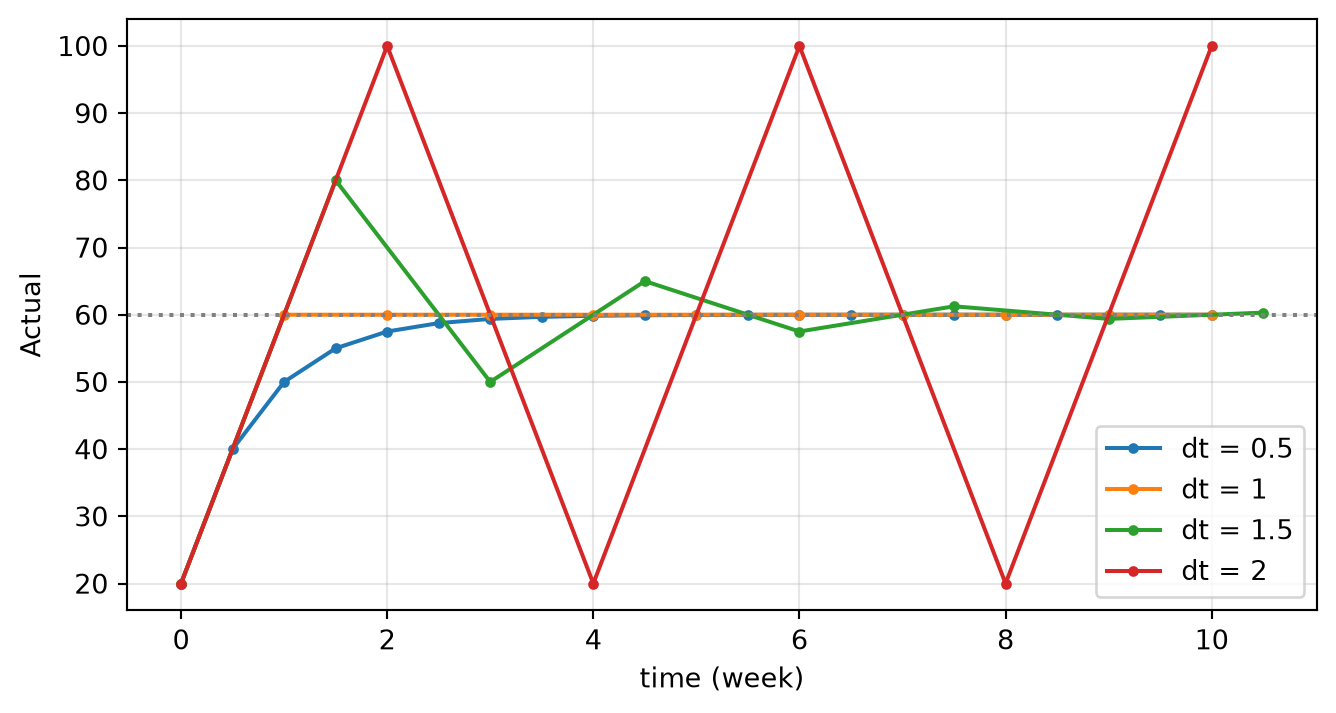

In [5]:
cg = lb.molecule("closegap")
fig, ax = plt.subplots(figsize=(8, 4))
for dt in (0.5, 1, 1.5, 2):
    run = cg.run(T=10, dt=dt, adjustment_time=1)["Actual"]
    run.plot(ax=ax, marker=".", label=f"dt = {dt}")
    print(f"dt {dt}: {run.round(1).tolist()[:7]}")
ax.axhline(60, ls=":", c="grey"); ax.set_ylabel("Actual"); ax.legend(); ax.grid(alpha=0.3)

At `dt = 0.5` the gap halves each step (20, 40, 50, 55, ...). At `dt = 1` the stock jumps to 60 in one step. At 1.5 it overshoots to 80 and then rings around the goal, an oscillation that the real system does not have. At 2 it bounces between 20 and 100 for ever. None of this belongs to the model: it is all arithmetic. That is why the step is chosen from the **shortest** time constant in the model, usually a quarter to a tenth of it, and then tested by halving.

**Try it.** Predict what `dt = 2.5` does, then run it. Why does the run not show what the arithmetic predicts?

<details><summary>Show a worked answer</summary>

The factor is 1 − 2.5 = −1.5, so the gap should flip sign and grow by half each step: an explosion. The run shows 20, 120, 0, 150, 0, ... The stock in this molecule is not allowed to go below zero, so each time the step would take it negative it is held at 0, and the explosion is hidden behind a strange sawtooth. A floor like that is a good idea for real stocks, but it can disguise a numerical failure, which is another reason to run the halving test.
</details>

In [6]:
print(cg.run(T=10, dt=2.5, adjustment_time=1)["Actual"].round(1).tolist())

[20.0, 120.0, 0.0, 150.0, 0.0]


## 3. A better estimate of the average flow

Instead of a smaller step, we can estimate the flow over the step better. **Runge-Kutta** methods sample the flow at more than one point inside the step and average. The second-order version takes a trial Euler step, computes the flow at the end of it, and moves the stock by the average of the start and end flows. The fourth-order version uses four samples. Here are all three on Decay, written in plain Python.

In [7]:
def flow(stock):
    return -stock / 1.0                   # decay with a decay time of 1

def euler(dt):
    s = 100.0
    for _ in range(round(1 / dt)):
        s = s + dt * flow(s)
    return s

def rk2(dt):
    s = 100.0
    for _ in range(round(1 / dt)):
        f_start = flow(s)
        f_end = flow(s + dt * f_start)    # flow after a trial Euler step
        s = s + dt * (f_start + f_end) / 2
    return s

def rk4(dt):
    s = 100.0
    for _ in range(round(1 / dt)):
        k1 = flow(s); k2 = flow(s + dt / 2 * k1); k3 = flow(s + dt / 2 * k2); k4 = flow(s + dt * k3)
        s = s + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
    return s

for dt in (0.5, 0.25, 0.125):
    print(f"dt {dt:<5}: error Euler {euler(dt) - exact:8.4f}, RK2 {rk2(dt) - exact:8.4f}, RK4 {rk4(dt) - exact:8.5f}")

dt 0.5  : error Euler -11.7879, RK2   2.2746, RK4  0.02914
dt 0.25 : error Euler  -5.1473, RK2   0.4650, RK4  0.00148
dt 0.125: error Euler  -2.4271, RK2   0.1054, RK4  0.00008


At the same step, RK2 is several times closer than Euler and RK4 is closer still. Halve the step and Euler's error halves (−5.1 to −2.4), RK2's falls by about four (0.46 to 0.11) and RK4's by more than ten. RK4 costs four flow calculations a step instead of one, so it pays off for smooth physical systems. For models of firms and people, whose parameters are uncertain to 10% or more and which often contain switches like `MIN` and `IF`, Euler with a well-tested step is usually enough, which is why LoopBricks uses it.

**Try it.** Use the same three functions on growth instead of decay: change `flow` to return `+0.03 * stock` and compare the methods after one year with `dt = 1`.

<details><summary>Show a worked answer</summary>

Exact growth for one year is 100 e⁰·⁰³ ≈ 103.0455. Euler with a year-long step gives 103 (simple interest), RK2 gives 103.045 and RK4 103.0455. For such a slow process even Euler is off by only 0.04%: errors matter when the step is long compared with the time constant (here about 33 years), not in themselves. Remember to set `flow` back to decay afterwards if you rerun the cells above.
</details>

## 4. White noise, pink noise and the modes of a model

Real demand is never flat. To make a model more realistic we can add a random effect, as a multiplier with an average of 1 so that it changes the variation but not the mean. The question is which kind of randomness.

* **White noise** draws a new, independent number every step. It has no memory, so it changes far faster than anything real.
* **Pink noise** is white noise passed through a first-order smooth (the same structure as the [Smooth](https://waelrash1.github.io/loopbricks/#/m/smooth) molecule). The smoothing time is the **correlation time**: roughly how long a high or low spell tends to last.

Since smoothing removes variation, the white noise going in must be scaled up so the pink noise coming out has the spread we want.

standard deviation: white 0.100, pink 0.094


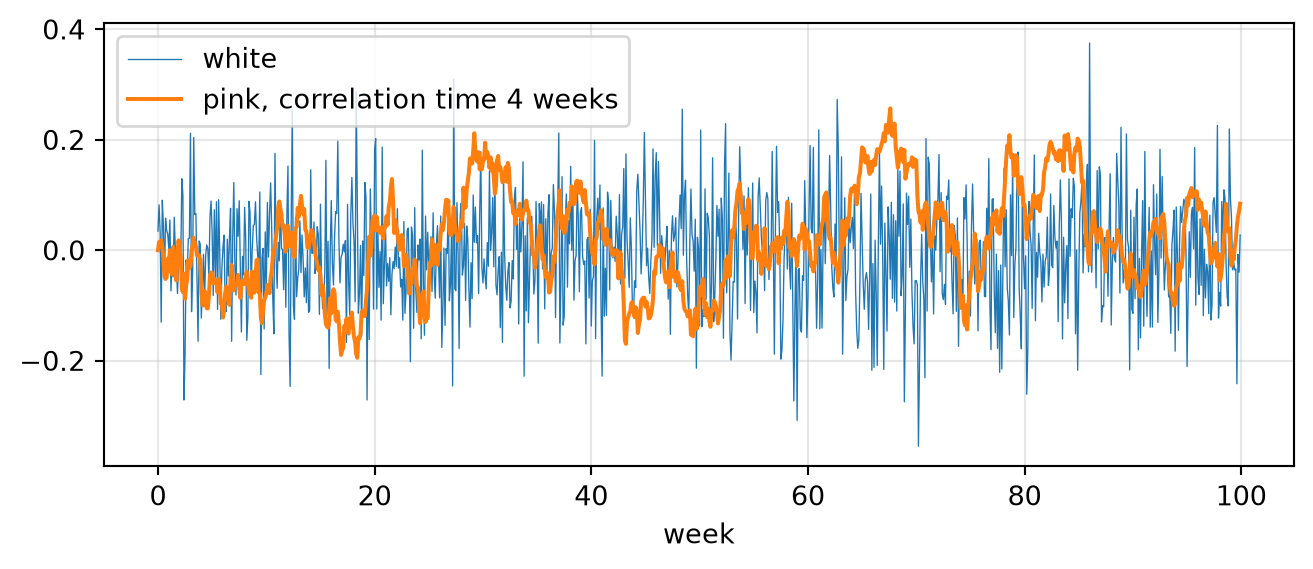

In [8]:
dt = 0.1
rng = np.random.default_rng(1)

def pink_noise(n, sd, corr_time, rng):
    """White noise passed through a first-order smooth, scaled so the result has standard deviation sd."""
    white = rng.normal(0, sd * np.sqrt(2 * corr_time / dt), n)
    x = np.zeros(n)
    for i in range(1, n):
        x[i] = x[i - 1] + dt * (white[i - 1] - x[i - 1]) / corr_time
    return x

n = round(500 / dt) + 1                      # 500 weeks
weeks = np.arange(n) * dt
white = rng.normal(0, 0.1, n)
pink = pink_noise(n, 0.1, 4, rng)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(weeks[:1000], white[:1000], lw=0.5, label="white")
ax.plot(weeks[:1000], pink[:1000], label="pink, correlation time 4 weeks")
ax.set_xlabel("week"); ax.legend(); ax.grid(alpha=0.3)
print(f"standard deviation: white {white.std():.3f}, pink {pink.std():.3f}")

Both have a spread of about 10%, but they look nothing alike. The white noise is a fuzz; the pink noise wanders up and down in spells of a few weeks, much more like real orders.

Now feed both into Stock Management with the supply line ignored, the case that has a damped cycle of about 33 weeks. The package runs a model with constant inputs, so we write the same two-stock model in a few lines of Python, check that it matches the package when there is no noise, and then add noise to demand. The model starts in balance (inventory 100), so any movement comes from the noise.

largest difference from the package: 0.0
white noise: inventory standard deviation 0.55, range 98.2 to 101.6
 pink noise: inventory standard deviation 2.87, range 93.5 to 108.6


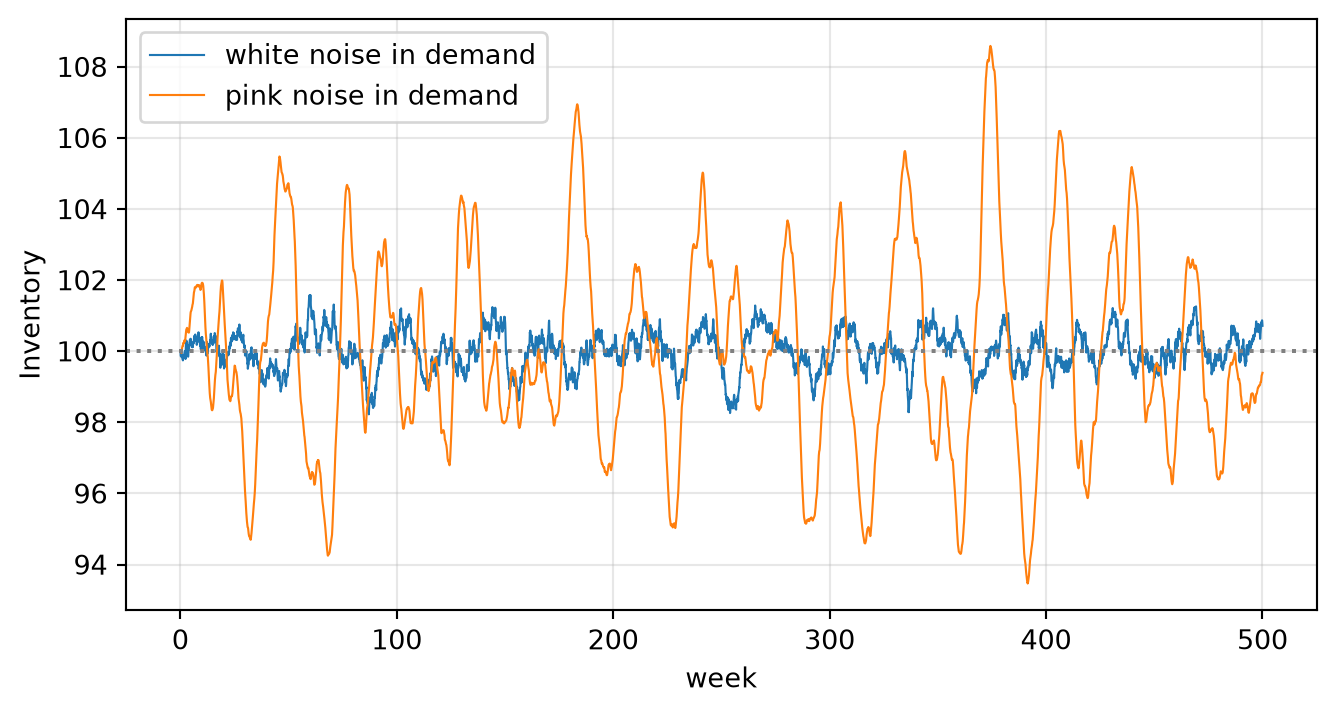

In [9]:
def stock_management(demand, inventory=60.0, supply_line=60.0, weight=0.0, desired=100, adj_time=4, delay=6):
    """Stock Management from the package, written out step by step so demand can change every step."""
    path = []
    for d in demand:
        orders = max(0.0, d + (desired - inventory) / adj_time + weight * (d * delay - supply_line) / adj_time)
        acquisition = supply_line / delay
        path.append(inventory)
        inventory += dt * (acquisition - d)
        supply_line += dt * (orders - acquisition)
    return np.array(path)

sm = lb.molecule("stockmgmt")
check = sm.run(T=80, supply_line_weight=0)["Inventory"].values
print("largest difference from the package:", np.abs(stock_management(np.full(801, 10.0)) - check).max())

fig, ax = plt.subplots(figsize=(8, 4))
for name, noise in (("white", white), ("pink", pink)):
    inv = stock_management(10 * (1 + noise), inventory=100)
    ax.plot(weeks, inv, lw=0.8, label=f"{name} noise in demand")
    print(f"{name:>5} noise: inventory standard deviation {inv.std():.2f}, range {inv.min():.1f} to {inv.max():.1f}")
ax.axhline(100, ls=":", c="grey"); ax.set_xlabel("week"); ax.set_ylabel("Inventory"); ax.legend(); ax.grid(alpha=0.3)

The hand-written model matches the package exactly. With the same 10% spread in demand, white noise barely moves inventory (it stays within about 98 to 102), while pink noise sets off swings from about 93 to 109, with a standard deviation more than five times larger. The swings come in slow waves, weeks long. White noise changes too fast for the stock to follow: an inventory adds up demand over time, and independent ups and downs cancel. Pink noise keeps pushing the same way for weeks, long enough to excite the model's mode. That is why models need correlated noise to show how they really respond (see Sterman 2000, appendix B), and why a model driven by white noise can look misleadingly calm.

**Try it.** Keep the spread at 10% and vary the correlation time: 0.5, 2, 4, 8, 16 and 32 weeks. Average the inventory standard deviation over five noise series for each. Which correlation time shakes the model most?

<details><summary>Show a worked answer</summary>

The cell below gives about 1.7, 2.9, 3.3, 3.2, 2.7 and 2.0. The response peaks for correlation times of around 4 to 8 weeks and falls off on both sides. Very short correlation times behave like white noise and cancel out. Very long ones change so slowly that the ordering rule keeps up with them, so there is little gap to correct. In between, the noise has most of its power near the model's own rhythm, and the model resonates. The system acts as a filter that picks out the frequencies near its mode.
</details>

In [10]:
for corr_time in (0.5, 2, 4, 8, 16, 32):
    sds = [stock_management(10 * (1 + pink_noise(n, 0.1, corr_time, np.random.default_rng(100 + k))), inventory=100).std()
           for k in range(5)]
    print(f"correlation time {corr_time:>4} weeks: inventory standard deviation {np.mean(sds):.2f}")

correlation time  0.5 weeks: inventory standard deviation 1.70
correlation time    2 weeks: inventory standard deviation 2.92
correlation time    4 weeks: inventory standard deviation 3.32


correlation time    8 weeks: inventory standard deviation 3.21


correlation time   16 weeks: inventory standard deviation 2.67
correlation time   32 weeks: inventory standard deviation 2.03


## Where next

- Back in the app: the [Simulation mechanics module](https://waelrash1.github.io/loopbricks/#/learn/mechanics) has diagrams of a single Euler and Runge-Kutta step and a step-by-step procedure for adding noise.
- Goal seeking, decay and growth, the three loops used here, are the subject of [First-order feedback](https://waelrash1.github.io/loopbricks/#/learn/first-order); the cycle that pink noise excites is in [Oscillation](https://waelrash1.github.io/loopbricks/#/learn/oscillation).
- The halving test is one of the model tests in [Testing and building confidence](https://waelrash1.github.io/loopbricks/#/learn/testing).